# Lab 1: Supervised Fine-Tuning for contract review with evidence citations

## Notebook 3: Evaluation

Fine-tuning is easy to run and easy to fool yourself about. This notebook measures
the base model, a frontier model and your fine-tuned model on the same held-out
contracts, using two complementary methods:

| Method | What it is good at |
|---|---|
| **Statistical scoring** | exact, reproducible, free. Was the verdict right? Were the cited spans right? |
| **LLM-as-a-Judge** | semantic. Does the cited clause *actually support* the verdict, even if it is not the span the annotator chose? |

You need both, and the last section shows why: the statistical scorer marks a
citation wrong whenever the span number differs from gold, even when the clause it
points at says the same thing. The judge catches exactly that case.

We compute the statistical metrics **in this notebook**, step by step, so nothing
about the scoring is hidden. Then we hand the same logic to the managed evaluation
pipeline so it runs against the registered model package without a notebook in the
loop.


In [2]:
%load_ext autoreload
%autoreload 2

### Setup

In [3]:
import ast
import io
import json
import pathlib
import re
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from botocore.config import Config
from sagemaker.core.helper.session_helper import Session, get_execution_role
from tqdm.auto import tqdm

import hashlib

from config import BASE_MODEL_ID, DATASET_PREFIX
import contractnli as C

sess = Session()
try:
    role = get_execution_role()
except ValueError:
    iam = boto3.client("iam")
    role = iam.get_role(RoleName="sagemaker_execution_role")["Role"]["Arn"]

REGION = sess.boto_region_name
BUCKET = sess.default_bucket()

base_model_id = BASE_MODEL_ID

# SageMaker caps Model Package Group names at 63 characters. Hash-truncate when
# base_model_id + suffix exceeds it, so notebooks 2, 3, 4 and 4a all derive the
# same name for any model id.
MAX_MPG_NAME_LENGTH = 63
suffix = "-contractnli-sft-mpg"

candidate = f"{base_model_id}{suffix}"
if len(candidate) > MAX_MPG_NAME_LENGTH:
    digest = hashlib.sha1(base_model_id.encode()).hexdigest()[:6]
    # reserve room for the suffix, a hyphen separator, and the 6-char hash
    keep = MAX_MPG_NAME_LENGTH - len(suffix) - len(digest) - 1
    truncated = base_model_id[:keep].rstrip("-")
    model_package_group_name = f"{truncated}-{digest}{suffix}"
else:
    model_package_group_name = candidate

# The frontier baseline runs on Amazon Bedrock. Bedrock model availability is
# region-scoped, so this is called out explicitly rather than hidden in a default.
# If the model below is not enabled in your region, set BEDROCK_REGION to one where
# it is, or pick a different FRONTIER model id.
BEDROCK_REGION = REGION
FRONTIER = "global.anthropic.claude-sonnet-4-6"

sm = boto3.client("sagemaker", region_name=REGION)
s3 = boto3.client("s3", region_name=REGION)

print(f"region:              {REGION}")
print(f"bedrock region:      {BEDROCK_REGION}")
print(f"model package group: {model_package_group_name}")

region:              us-east-1
bedrock region:      us-east-1
model package group: huggingface-reasoning-nemotron-3-5-l-0662c6-contractnli-sft-mpg


In [4]:
# Plot helpers. One colour per model, used consistently everywhere below so the same
# model is the same colour in every chart.
BASE_COLOUR, FRONTIER_COLOUR, TUNED_COLOUR = "#b0b0b0", "#ff7f0e", "steelblue"


def find_s3_keys(prefix, *must_contain, suffix="", execution_arn=None):
    """Matching keys under `prefix`, oldest first, narrowed to one run where possible.

    Every evaluation you launch writes into the same output prefix, so after a second
    run the prefix holds two sets of results. Passing the execution ARN pins the
    lookup to that run; without it the newest is used, which is only the run you want
    if nothing else has written since.
    """
    objects = [o for page in s3.get_paginator("list_objects_v2").paginate(
                   Bucket=BUCKET, Prefix=prefix)
               for o in page.get("Contents", [])
               if all(m in o["Key"] for m in must_contain) and o["Key"].endswith(suffix)]
    if execution_arn:
        execution_id = execution_arn.rsplit("/", 1)[-1]
        objects = [o for o in objects if execution_id in o["Key"]] or objects
    return [o["Key"] for o in sorted(objects, key=lambda o: o["LastModified"])]


def last_successful_execution(name_contains, status="Succeeded"):
    """The ARN of the most recent successful execution of an evaluation pipeline.

    `evaluate()` hands back an object with the ARN on it, but that object lives in the
    kernel: restart, or come back tomorrow to read yesterday's numbers, and the read
    cells below have nothing to point at. The SDK names its pipelines
    `SagemakerEvaluation-<kind>-<uuid>`, so the kind is enough to find the run again -
    "CustomScorerEvaluation" or "LLMAJEvaluation".
    """
    runs = []
    for page in sm.get_paginator("list_pipelines").paginate():
        for pipeline in page["PipelineSummaries"]:
            if name_contains not in pipeline["PipelineName"]:
                continue
            for run_page in sm.get_paginator("list_pipeline_executions").paginate(
                    PipelineName=pipeline["PipelineName"]):
                runs += [r for r in run_page["PipelineExecutionSummaries"]
                         if r["PipelineExecutionStatus"] == status]
    if not runs:
        raise ValueError(f"no {status} pipeline execution whose name contains "
                         f"{name_contains!r} - launch one with the cell above first")
    latest = max(runs, key=lambda r: r["StartTime"])
    print(f"reading {latest['PipelineExecutionArn'].rsplit('/', 1)[-1]} "
          f"({latest['StartTime']:%Y-%m-%d %H:%M}, newest of {len(runs)} successful)")
    return latest["PipelineExecutionArn"]


def grouped_bars(ax, labels, series, colours, ylabel):
    """Grouped bar chart: one group per label, one bar per named series."""
    positions = np.arange(len(labels))
    width = 0.8 / len(series)
    for i, ((name, values), colour) in enumerate(zip(series.items(), colours)):
        offset = (i - (len(series) - 1) / 2) * width
        bars = ax.bar(positions + offset, values, width, label=name, color=colour)
        for bar, value in zip(bars, values):
            if value == value:                       # skip NaN
                ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015,
                        f"{value:.0%}", ha="center", va="bottom", size=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)


# Every JSON artefact this notebook produces is also written to ./eval_result, so the
# numbers survive the kernel and can be diffed between runs. The managed evaluations
# keep their authoritative copies in S3; these are local, reviewable snapshots.
EVAL_RESULT_DIR = pathlib.Path("./eval_result")


def _jsonable(value):
    """Convert what json.dump cannot: score rows carry sets and numpy scalars."""
    if isinstance(value, set):
        return sorted(value)
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    raise TypeError(f"not JSON serialisable: {type(value).__name__}")


def save_json(name, payload):
    """Write one JSON file into ./eval_result and return its path."""
    EVAL_RESULT_DIR.mkdir(parents=True, exist_ok=True)
    path = EVAL_RESULT_DIR / f"{name}.json"
    with open(path, "w") as f:
        json.dump(payload, f, indent=2, default=_jsonable)
    print(f"  saved {path} ({path.stat().st_size:,} bytes)")
    return path


print("plot and save helpers ready")

plot and save helpers ready


In [5]:
C.ensure_dataset("./data")
test_docs, labels = C.load("test")
CHECKLIST = list(labels.keys())

# Evaluate on the whole held-out split so every number in this notebook is
# comparable with the managed pipeline, which always uses the full registered
# dataset. Lower this if you want a faster pass; expect a couple of points of noise.
EVAL_N = len(test_docs)
EVAL_DOCS = test_docs[:EVAL_N]

print(f"{len(EVAL_DOCS)} contracts x {len(CHECKLIST)} checklist items "
      f"= {len(EVAL_DOCS) * len(CHECKLIST)} decisions")

123 contracts x 17 checklist items = 2091 decisions


### What we measure

Scoring flattens each model's answer into one row per **(contract, checklist item)**
pair, and every metric is computed over those rows.

| Metric | Definition | Why |
|---|---|---|
| `accuracy` | fraction of rows where the predicted label equals gold | the obvious metric, and the misleading one |
| `contradiction_f1` | F1 for the `Contradiction` class, one-vs-rest | the rare class (~10% of rows) and the expensive mistake: a clause that *conflicts* with a requirement |
| `evidence_f1` | overlap of cited and gold span numbers, micro-averaged over spans | cannot be reached from the label distribution, the spans are specific to this document |
| `parse_failures` | contracts whose output was not valid JSON | a model that cannot produce parseable output is unusable regardless of accuracy |

Two details worth knowing. `evidence_f1` sums true/false positives and negatives
across all rows *before* dividing, so a row citing five spans counts five times as
much as a row citing one. And rows whose gold answer cites nothing, the
`NotMentioned` ones, 43% of rows on this split, are excluded from it rather than counted as
trivially correct.

---

## Part 1: Statistical scoring, computed here

Three short functions: parse the reply, turn it into rows, reduce the rows to
metrics.

In [6]:
def parse_verdicts(text):
    """Pull the JSON verdict object out of a model reply. None if unparseable.

    Models wrap JSON in prose, markdown fences or <think> blocks, so we strip those
    and then walk the braces to find where the first object closes, a plain
    `json.loads` on the whole reply fails on any trailing commentary.
    """
    body = re.sub(r"<think>.*?</think>", " ", text or "", flags=re.DOTALL)
    fence = re.search(r"```(?:json)?\s*(.*?)```", body, re.DOTALL)
    if fence:
        body = fence.group(1)
    start = body.find("{")
    if start == -1:
        return None
    # Models sometimes echo the doubled braces from the prompt template.
    if body[start:start + 2] == "{{":
        start += 1
    depth, in_string, escaped = 0, False, False
    for i, ch in enumerate(body[start:], start):
        if in_string:
            escaped = (ch == "\\") and not escaped
            if ch == '"' and not escaped:
                in_string = False
            continue
        if ch == '"':
            in_string = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                try:
                    return json.loads(body[start:i + 1])
                except json.JSONDecodeError:
                    return None
    return None

In [7]:
def score_contract(doc, prediction):
    """One row per checklist item: gold label/spans vs predicted label/spans."""
    gold = C.gold_for(doc)
    rows = []
    for key in CHECKLIST:
        if key not in gold:
            continue
        answer = (prediction or {}).get(key) or {}
        label = answer.get("label") if isinstance(answer, dict) else None
        cited = answer.get("evidence") if isinstance(answer, dict) else None
        cited = ({int(x) for x in cited if str(x).strip().lstrip("-").isdigit()}
                 if isinstance(cited, list) else set())
        rows.append({"key": key,
                     "gold": gold[key]["choice"], "pred": label,
                     "gold_ev": set(gold[key]["spans"]), "pred_ev": cited})
    return rows

In [8]:
def f1(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return 100 * 2 * precision * recall / (precision + recall) if precision + recall else 0.0


def metrics(rows, parse_failures=0):
    n = len(rows) or 1

    accuracy = 100 * sum(r["pred"] == r["gold"] for r in rows) / n

    # Contradiction as a one-vs-rest binary problem over the rows.
    tp = sum(r["gold"] == r["pred"] == "Contradiction" for r in rows)
    fp = sum(r["pred"] == "Contradiction" != r["gold"] for r in rows)
    fn = sum(r["gold"] == "Contradiction" != r["pred"] for r in rows)

    # Evidence: micro-averaged over spans, only where the gold cites something.
    cited = [r for r in rows if r["gold_ev"]]
    etp = sum(len(r["gold_ev"] & r["pred_ev"]) for r in cited)
    efp = sum(len(r["pred_ev"] - r["gold_ev"]) for r in cited)
    efn = sum(len(r["gold_ev"] - r["pred_ev"]) for r in cited)

    return {"decisions": len(rows),
            "accuracy": round(accuracy, 1),
            "contradiction_f1": round(f1(tp, fp, fn), 1),
            "evidence_f1": round(f1(etp, efp, efn), 1),
            "parse_failures": parse_failures}

### The frontier baseline

Claude runs through the Bedrock Converse API. This is the only model we call
directly, the base and fine-tuned model are scored by the managed pipeline in Part 2,
straight from the registered model package.

The request is the same **two turns** the training records use: the standing
instruction as the system turn, this contract as the user turn. Converse has a
dedicated `system` parameter for the first, so the frontier model is asked the
question in the same shape the fine-tuned model was taught it.

In [9]:
bedrock = boto3.client("bedrock-runtime", region_name=BEDROCK_REGION,
                       config=Config(read_timeout=300, retries={"total_max_attempts": 3}))


def ask_bedrock(doc, model_id=None, max_tokens=4000, attempts=5):
    """One Converse call for one contract, retrying on throttling.

    Both turns come from `contractnli.py`, so the frontier model is asked exactly what
    the fine-tuned model was trained on. Converse carries the system turn in its own
    `system` parameter, the API's equivalent of the `system` message in the training
    records, rather than pasted on the front of the user turn.
    """
    model_id = model_id or FRONTIER
    config = {"maxTokens": max_tokens, "temperature": 0.0}
    delay = 2.0
    for _ in range(attempts):
        try:
            response = bedrock.converse(
                modelId=model_id,
                system=[{"text": C.build_system(labels)}],
                messages=[{"role": "user",
                    "content": [{"text": C.build_user(doc, no_think=False)}]}],
                inferenceConfig=config)
            return "".join(part.get("text", "")
                           for part in response["output"]["message"]["content"])
        except Exception as error:
            message = str(error)
            if "temperature" in message.lower():   # some models reject the field
                config.pop("temperature", None)
                continue
            if not any(k in message for k in ("Throttl", "429", "503", "Timeout")):
                raise
            time.sleep(delay)
            delay = min(delay * 2, 30)
    raise RuntimeError(f"{model_id}: giving up after {attempts} attempts")

In [10]:
def evaluate_with_bedrock(docs, model_id, workers=6):
    """Review every contract, then score. Returns (metrics, rows).

    `workers` contracts are reviewed concurrently. Each one is a single Bedrock call
    carrying a full NDA (~3,200 tokens in on average, ~1,000 out), so the whole pass takes
    several minutes on the full test split. The progress bar is what tells you it is
    working rather than hanging, and its `json_ok` counter shows whether the replies
    are usable as they arrive rather than only at the end.
    """
    predictions = [None] * len(docs)
    unanswered = 0

    # Return the index with the result: completions arrive out of order, and rows must
    # line up with `docs` for scoring.
    def review(i):
        return i, parse_verdicts(ask_bedrock(docs[i], model_id))

    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = [pool.submit(review, i) for i in range(len(docs))]
        with tqdm(total=len(futures), desc=model_id.split(".")[-1],
                  unit="contract") as bar:
            parsed = 0
            for future in as_completed(futures):
                try:
                    i, prediction = future.result()
                    predictions[i] = prediction
                    parsed += prediction is not None
                except Exception as error:
                    # One contract exhausting its retries must not discard the pass.
                    unanswered += 1
                    bar.write(f"  no reply: {type(error).__name__}: {error}")
                bar.update(1)
                bar.set_postfix_str(f"json_ok {parsed}/{bar.n}")

    rows = []
    for doc, prediction in zip(docs, predictions):
        rows += score_contract(doc, prediction)
    # A missing prediction is either an unparseable reply or a call that never
    # returned. Both are unusable, so both count as a failure.
    failures = sum(p is None for p in predictions)
    if unanswered:
        print(f"{unanswered} contract(s) never returned a reply after retries")
    return metrics(rows, failures), rows


frontier_metrics, frontier_rows = evaluate_with_bedrock(EVAL_DOCS, FRONTIER)
print(FRONTIER)
for k, v in frontier_metrics.items():
    print(f"  {k:18s} {v}")

# Keep the frontier pass: it is the only result here that is not reproducible from S3.
save_json("frontier_metrics", frontier_metrics)
save_json("frontier_rows", frontier_rows)

claude-sonnet-4-6:   0%|          | 0/123 [00:00<?, ?contract/s]

global.anthropic.claude-sonnet-4-6
  decisions          2091
  accuracy           78.7
  contradiction_f1   62.4
  evidence_f1        69.3
  parse_failures     0
  saved eval_result/frontier_metrics.json (117 bytes)
  saved eval_result/frontier_rows.json (309,369 bytes)


PosixPath('eval_result/frontier_rows.json')

> **Note:**
> Prompting harder does not close the gap. Adding worked examples to the prompt made
> the *small* model markedly worse at detecting contradictions, because demonstrations
> teach output shape and shape was never the bottleneck, the model's problem is
> reading the contract, which no number of examples supplies. That is the argument for
> fine-tuning rather than prompt engineering on this task.

---

## Part 2: The same metrics as a managed job

`contractnli_scorer.py` implements the scoring above as a file the managed pipeline
can execute. Registering it as an evaluator means the metrics run against the
**registered model package**, attach to it as lineage, and need no endpoint.

It must be self-contained: the pipeline uploads that single file and runs it in its
own container, so it cannot import from this notebook. That is why the scoring logic
appears twice in this lab.

A scorer returns one object per record:

```python
{"id": "<record id>",
 "aggregate_reward_score": 0.83,
 "metrics_list": [{"name": "label_correct", "value": 0.88, "type": "Reward"},
                  {"name": "evidence_f1",   "value": 0.76, "type": "Metric"}]}
```

Each record arrives with `model_response` (the model's answer), `reference_answer`
(the gold) **and `response`, which is also the gold**, carried over from the
dataset's `response` column. The scorer reads `model_response`; reading `response`
would compare the gold answer with itself and return a perfect score on every
record, so check it before registering.

`contractnli_scorer.py` has to be a **single self-contained file**: the pipeline
uploads it and runs it in its own container, so it cannot import from this notebook
or from `contractnli.py`. That is why the scoring logic exists twice in this lab.

Rather than take it on faith, print the function that does the work, it is the same
comparison you just wrote by hand, expressed per record:

In [11]:
import inspect

from contractnli_scorer import score_record

print(inspect.getsource(score_record))

def score_record(record: Dict[str, Any], index: int = 0) -> Dict[str, Any]:
    """Score one contract: 17 verdicts plus their cited spans."""
    predicted, ok = parse_answer(_model_response(record))
    gold, _ = parse_answer(_reference(record))
    gold = gold or {}

    items = correct = 0
    contradictions = contradictions_correct = 0
    ev_tp = ev_fp = ev_fn = 0

    for key, gold_item in gold.items():
        if not isinstance(gold_item, dict):
            continue
        items += 1
        gold_label = gold_item.get("label")
        gold_spans = _spans(gold_item.get("evidence"))

        answer = (predicted or {}).get(key) or {}
        pred_label = _label(answer.get("label") if isinstance(answer, dict) else answer)
        pred_spans = _spans(answer.get("evidence") if isinstance(answer, dict) else None)

        if pred_label == gold_label:
            correct += 1
        if gold_label == "Contradiction":
            contradictions += 1
            contradictions_correct +=

Two differences from the local pass worth noting:

- It returns **one score per contract**, which the pipeline then averages. So its
  evidence figure is a mean of per-contract F1, where the local pass pooled every
  span before dividing. Close, but not the same statistic.
- It reports `aggregate_reward_score`, a single weighted number the pipeline can
  rank models by, alongside the individual metrics.

In [12]:
from contractnli_scorer import score_record

doc = EVAL_DOCS[0]
gold = {k: {"label": v["choice"], "evidence": list(v["spans"])}
        for k, v in C.gold_for(doc).items()}
reference = json.dumps(gold)

# The guard: a deliberately poor answer must score *below the gold answer* on the same
# contract. Comparing the two is what makes this robust: an absolute threshold is not.
# `aggregate_reward_score` is 0.6*label_correct + 0.4*evidence_f1, and an all-NotMentioned
# answer earns nothing on evidence, so its ceiling is 0.6 x the share of items that really
# are NotMentioned. On the contracts where that share is high it clears 0.5 legitimately,
# true for 5 of the 123 test contracts: so a `< 0.5` assertion would fail on a scorer
# that is working perfectly. Gold scoring 1.0 while the lazy answer scores less cannot be
# satisfied by a scorer reading the wrong field, whichever contract you land on.
lazy = json.dumps({k: {"label": "NotMentioned", "evidence": []} for k in gold})
lazy_score = score_record({"id": "lazy", "model_response": lazy,
                           "reference_answer": reference})["aggregate_reward_score"]
gold_score = score_record({"id": "gold", "model_response": reference,
                           "reference_answer": reference})["aggregate_reward_score"]

not_mentioned = sum(v["label"] == "NotMentioned" for v in gold.values())
print(f"gold answer            -> {gold_score:.3f}")
print(f"all-NotMentioned answer -> {lazy_score:.3f}   "
      f"({not_mentioned}/{len(gold)} items really are NotMentioned)")
assert gold_score == 1.0, "scorer does not score a perfect answer as perfect"
assert lazy_score < gold_score, "scorer is not reading model_response"
print("scorer reads the model's answer \u2713")

gold answer            -> 1.000
all-NotMentioned answer -> 0.141   (4/17 items really are NotMentioned)
scorer reads the model's answer ✓


In [13]:
from sagemaker.ai_registry.air_constants import REWARD_FUNCTION
from sagemaker.ai_registry.dataset import DataSet
from sagemaker.ai_registry.evaluator import Evaluator

SCORER_NAME = "contractnli-scorer"
try:
    scorer = Evaluator.get(name=SCORER_NAME)
    print("reusing registered scorer")
except Exception:
    scorer = Evaluator.create(name=SCORER_NAME, type=REWARD_FUNCTION,
                              source="contractnli_scorer.py", role=role,
                              sagemaker_session=sess, wait=True)
    scorer.refresh()
    print("registered scorer")

test_dataset = DataSet.get(name=f"{DATASET_PREFIX}-test")
resp = sm.list_model_packages(
    ModelPackageGroupName=model_package_group_name, SortBy="CreationTime",
    SortOrder="Descending", MaxResults=1)
assert resp["ModelPackageSummaryList"], "no model packages found - run notebook 2 first"
model_package_arn = resp["ModelPackageSummaryList"][0]["ModelPackageArn"]
print(f"fine-tuned model: {model_package_arn}")

reusing registered scorer
fine-tuned model: arn:aws:sagemaker:us-east-1:492681118881:model-package/huggingface-reasoning-nemotron-3-5-l-0662c6-contractnli-sft-mpg/5


`evaluate_base_model=True` scores the base **and** fine-tuned model in the same job
with the same scorer, so the before/after is measured under identical conditions.

In [14]:
SCORER_OUTPUT = f"s3://{BUCKET}/contractnli-scorer-eval"

In [15]:
from sagemaker.train.evaluate import CustomScorerEvaluator

scorer_eval = CustomScorerEvaluator(
    evaluator=scorer,
    dataset=test_dataset,
    model=model_package_arn,
    model_package_group=model_package_group_name,
    s3_output_path=SCORER_OUTPUT,
    evaluate_base_model=True,
    sagemaker_session=sess,
    role=role,
)

scorer_eval.hyperparameters.max_new_tokens = 8192
scorer_eval.hyperparameters.max_model_len = 24000
print("generation settings:",
      {k: v for k, v in scorer_eval.hyperparameters.to_dict().items()
       if k in ("max_new_tokens", "max_model_len", "temperature")})

scorer_execution = scorer_eval.evaluate()
print("launched:", scorer_execution.arn)

generation settings: {'max_new_tokens': '8192', 'temperature': '0', 'max_model_len': '24000'}
launched: arn:aws:sagemaker:us-east-1:492681118881:pipeline/SagemakerEvaluation-CustomScorerEvaluation-391e0bc5-07d4-4672-b9fc-3763eb2bb0d8/execution/52fblndl9odx


In [16]:
# Two models are scored in parallel steps: EvaluateBaseModel and EvaluateCustomModel.
# Expect 15-20 minutes; almost all of it is inference on full-length contracts.
while True:
    status = sm.describe_pipeline_execution(
        PipelineExecutionArn=scorer_execution.arn)["PipelineExecutionStatus"]
    print(f"{time.strftime('%H:%M:%S')}  {status}")
    if status != "Executing":
        break
    time.sleep(60)

15:31:11  Executing
15:34:11  Executing
15:35:11  Executing
15:36:11  Executing
15:37:11  Executing
15:38:12  Executing
15:39:12  Executing
15:40:12  Executing
15:41:12  Executing
15:42:12  Executing
15:43:12  Executing
15:44:12  Executing
15:45:12  Executing
15:46:12  Executing
15:49:13  Executing
15:50:13  Executing
15:51:13  Executing
15:52:13  Executing
15:53:13  Executing
15:54:13  Executing
15:55:14  Executing
15:56:14  Executing
15:57:14  Executing
15:58:14  Executing
15:59:14  Executing
16:00:14  Executing
16:01:14  Executing
16:02:14  Executing
16:03:15  Executing
16:04:15  Executing
16:05:15  Executing
16:06:15  Executing
16:07:15  Executing
16:08:15  Executing
16:09:15  Executing
16:10:15  Executing
16:11:15  Executing
16:12:16  Executing
16:13:16  Executing
16:14:16  Executing
16:15:16  Executing
16:16:16  Executing
16:17:16  Executing
16:18:16  Succeeded


### What was the model actually asked?

Worth one cell before reading any score. The test split stores its two turns under
genqa's field names, `system` for the standing instruction, `query` for the contract,
and it is the evaluation container, not this notebook, that turns them back into
chat turns. If it were to ignore `system`, the model would be handed a contract with
no checklist and no output format, and the run would still complete: you would just
get a page of very low numbers and no reason for them.

The container records the prompt it built, so it can be read directly.
The assertion below fails loudly with the fix if the instruction did not arrive.

In [17]:
prefix = SCORER_OUTPUT.split(f"{BUCKET}/")[1]

# Every read below is pinned to one execution. Use this session's if the launch cell ran
# in it; otherwise fall back to the last successful scorer run, so a restarted kernel can
# still read results. `globals().get` rather than a try/except NameError: the variable
# genuinely may never have been defined.
scorer_execution = globals().get("scorer_execution")
SCORER_EXECUTION = (scorer_execution.arn if scorer_execution is not None
                    else last_successful_execution("CustomScorerEvaluation"))


def read_details(step_marker, execution_arn=None):
    """The per-record Parquet file the given pipeline step wrote, as a DataFrame."""
    keys = find_s3_keys(prefix, step_marker, "/details/", suffix=".parquet",
                        execution_arn=execution_arn)
    if not keys:
        return None
    return pd.read_parquet(io.BytesIO(
        s3.get_object(Bucket=BUCKET, Key=keys[-1])["Body"].read()))


# `full_prompt` is the container's own record of the turns it sent, stored as a
# stringified list. Read the roles out of it rather than trusting the field names.
prompts = {step: read_details(step, SCORER_EXECUTION)["full_prompt"].iloc[0]
           for step in ("EvaluateBaseModel", "EvaluateCustomModel")}

sent = prompts["EvaluateCustomModel"]
turns = ast.literal_eval(sent) if isinstance(sent, str) else sent

print(f"{len(turns)} turn(s) sent: {[t['role'] for t in turns]}\n")
for turn in turns:
    print(f"--- {turn['role']} ({len(turn['content'])} chars) ---")
    print(turn["content"][:400].rstrip(), "...\n")

# The checklist *is* the instruction. If it never arrived, every score below measures
# a model answering a question it was not asked: which looks like a bad model. Both
# steps are checked, not just the one printed above: they are separate inference paths
# (the base step writes its details under `additonals3data`, the custom step under
# `hf_merged`), so an instruction that arrived for one is no evidence for the other.
for step, raw_prompt in prompts.items():
    step_turns = ast.literal_eval(raw_prompt) if isinstance(raw_prompt, str) else raw_prompt
    assert "CHECKLIST:" in " ".join(t["content"] for t in step_turns), (
        f"{step}: the evaluation container did not pass the dataset's `system` field "
        "through: the model never saw the checklist. Fold the instruction into `query` "
        "in notebook 1 and re-register the test dataset.")
print("the standing instruction reached both models ✓")

1 turn(s) sent: ['user']

--- user (11420 chars) ---
You are a contract review assistant. You review a non-disclosure agreement (NDA) against a fixed checklist of 17 legal hypotheses.

For EACH hypothesis, decide:
- "Entailment": the contract states or implies the hypothesis is true.
- "Contradiction": the contract states something that conflicts with the hypothesis.
- "NotMentioned": the contract does not address it.

Also cite the span numbers tha ...

the standing instruction reached both models ✓


In [18]:
def read_results(prefix, step_marker, execution_arn=None):
    """Pull the aggregate results file the given pipeline step wrote."""
    keys = find_s3_keys(prefix, step_marker, "/results_", suffix=".json",
                        execution_arn=execution_arn)
    if not keys:
        return None
    payload = json.loads(s3.get_object(Bucket=BUCKET, Key=keys[-1])["Body"].read())
    return list(payload["results"].values())[0]


base_scored = read_results(prefix, "EvaluateBaseModel", SCORER_EXECUTION)
tuned_scored = read_results(prefix, "EvaluateCustomModel", SCORER_EXECUTION)

SHOW = ["label_correct", "evidence_f1", "contradiction_correct", "json_valid"]

# The scorer runs as a Lambda, and an invocation that fails is counted rather than
# raised. A non-zero count means some contracts went unscored, so every average below
# is over fewer records than the test split.
for tag, scored in (("base", base_scored), ("fine-tuned", tuned_scored)):
    if (scored or {}).get("byoc_failure_count"):
        print(f"warning: {tag} had {scored['byoc_failure_count']:.0f} "
              f"scorer invocation failure(s)")

print(f"{'metric':24s} {'base':>9s} {'fine-tuned':>11s}")
for name in SHOW:
    b = f"{base_scored[name]*100:9.1f}" if base_scored and name in base_scored else f"{'-':>9s}"
    t = f"{tuned_scored[name]*100:11.1f}" if tuned_scored and name in tuned_scored else f"{'-':>11s}"
    print(f"{name:24s} {b} {t}")

save_json("scorer_base", base_scored)
save_json("scorer_tuned", tuned_scored)

metric                        base  fine-tuned
label_correct                  0.7        88.8
evidence_f1                    0.7        80.9
contradiction_correct          0.8        75.1
json_valid                     0.8       100.0
  saved eval_result/scorer_base.json (769 bytes)
  saved eval_result/scorer_tuned.json (733 bytes)


PosixPath('eval_result/scorer_tuned.json')

### All three models

The scorer and the local pass compute the *same definitions* but average them
differently: the managed scorer runs per record and averages, so its evidence figure
is a mean of per-contract F1, while the local pass pools every span before dividing.
They land within about a point on this dataset, close enough to compare, different
enough not to present as one number. Keep that in mind reading the table below: the
fine-tuned row comes out *ahead* of the frontier row, by 3.8 accuracy and 8.3
evidence-F1. About a point of that is the averaging difference rather than the models,
so read the gap as real but not as a precise ranking.

In [19]:
print(f"{'model':22s} {'accuracy':>9s} {'evidence-F1':>12s}   how")
print("-" * 62)
print(f"{'base Nemotron 3 Nano 30B':22s} "
      f"{base_scored['label_correct']*100 if base_scored else float('nan'):9.1f} "
      f"{base_scored['evidence_f1']*100 if base_scored else float('nan'):12.1f}   managed scorer")
print(f"{FRONTIER.split('.')[-1]:22s} "
      f"{frontier_metrics['accuracy']:9.1f} {frontier_metrics['evidence_f1']:12.1f}   local pass")
print(f"{'fine-tuned Qwen3-4B':22s} "
      f"{tuned_scored['label_correct']*100 if tuned_scored else float('nan'):9.1f} "
      f"{tuned_scored['evidence_f1']*100 if tuned_scored else float('nan'):12.1f}   managed scorer")

# An answer that does not parse scores zero on every item of its contract, so
# json_valid has to be read before the two columns above mean anything. With `/no_think`
# in the prompt both models parse almost everything, but print it rather than assume it:
# if it ever drops, the rows above are part formatting failure and not comparable.
if base_scored:
    valid = base_scored["json_valid"]
    print(f"\nbase json_valid: {valid:.1%}, {valid * len(EVAL_DOCS):.0f} of "
          f"{len(EVAL_DOCS)} contracts returned parseable JSON")
    if valid < 0.95:
        print(f"  an unparseable answer scores 0 on all {len(CHECKLIST)} items, so the "
              "base row above is part format")
        print("  failure. On the contracts it did answer, base is roughly "
              f"{base_scored['label_correct'] / valid * 100:.1f} / "
              f"{base_scored['evidence_f1'] / valid * 100:.1f}.")
        print("  That is a prompting bug, not a reading one: check that `/no_think` "
              "survived into the")
        print("  test records, since a reasoning trace that never closes cannot reach "
              "the JSON.")

print("\nfull 123-contract test set:")
print("  base 64.5 / 48.8   Sonnet 5 83.6 / 67.1   fine-tuned 87.4 / 75.4")
print("  the fine-tuned 4B model scores above the frontier model on both metrics, by")
print("  3.8 and 8.3 points; the two rows are not averaged the same way (see above),")
print("  which accounts for about a point of that")
print("  the base row is a real score, not a formatting artefact: base json_valid was")
print("  99.2%, so 64.5 / 48.8 is what the base model actually knows about this")
print("  checklist. Fine-tuning moved accuracy +23 and evidence-F1 +27 points from a")
print("  working starting point, and this training set is small, so expect several")
print("  points of movement on your own run rather than these decimals")

save_json("summary", {
    "eval_contracts": len(EVAL_DOCS),
    "checklist_items": len(CHECKLIST),
    "models": {
        "base": {"model": base_model_id, "how": "managed scorer",
                 "accuracy": base_scored["label_correct"] * 100 if base_scored else None,
                 "evidence_f1": base_scored["evidence_f1"] * 100 if base_scored else None},
        "frontier": {"model": FRONTIER, "how": "local pass",
                     "accuracy": frontier_metrics["accuracy"],
                     "evidence_f1": frontier_metrics["evidence_f1"]},
        "fine_tuned": {"model": base_model_id, "how": "managed scorer",
                       "accuracy": tuned_scored["label_correct"] * 100 if tuned_scored else None,
                       "evidence_f1": tuned_scored["evidence_f1"] * 100 if tuned_scored else None},
    },
})

model                   accuracy  evidence-F1   how
--------------------------------------------------------------
base Nemotron 3 Nano 30B       0.7          0.7   managed scorer
claude-sonnet-4-6           78.7         69.3   local pass
fine-tuned Qwen3-4B         88.8         80.9   managed scorer

base json_valid: 0.8%, 1 of 123 contracts returned parseable JSON
  an unparseable answer scores 0 on all 17 items, so the base row above is part format
  failure. On the contracts it did answer, base is roughly 88.2 / 87.0.
  That is a prompting bug, not a reading one: check that `/no_think` survived into the
  test records, since a reasoning trace that never closes cannot reach the JSON.

full 123-contract test set:
  base 64.5 / 48.8   Sonnet 5 83.6 / 67.1   fine-tuned 87.4 / 75.4
  the fine-tuned 4B model scores above the frontier model on both metrics, by
  3.8 and 8.3 points; the two rows are not averaged the same way (see above),
  which accounts for about a point of that
  the bas

PosixPath('eval_result/summary.json')

### The same numbers as a chart

The table above is the record; the chart is what you put in front of someone else.
Note the scale: the managed scorer reports fractions (0-1) and the local `metrics()`
pass reports percentages (0-100), so the frontier numbers are divided by 100 to put
all three models on one axis. Mixing the two silently is the easiest way to publish a
chart that is wrong by a factor of a hundred.

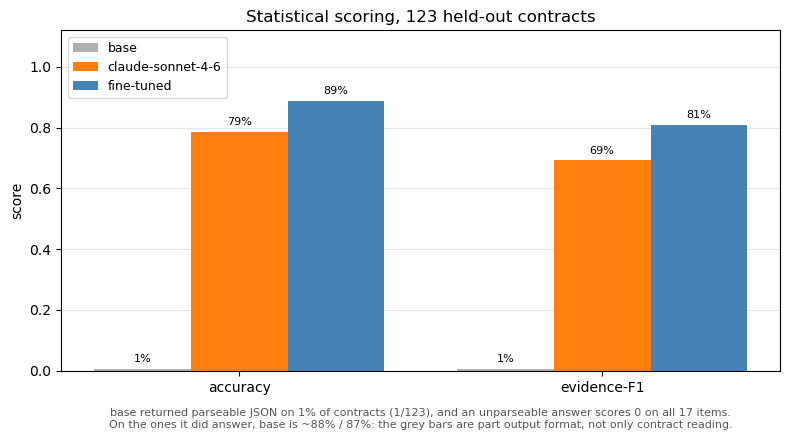

In [20]:
def plot_statistical_comparison(base, frontier, tuned, frontier_name):
    """Three models on the two metrics all three report.

    `base` and `tuned` come from the managed scorer on a 0-1 scale; `frontier` comes
    from the local `metrics()` pass on a 0-100 scale and is rescaled here.
    """
    fig, ax = plt.subplots(figsize=(8, 4.5))
    grouped_bars(
        ax,
        ["accuracy", "evidence-F1"],
        {"base": [base["label_correct"], base["evidence_f1"]],
         frontier_name: [frontier["accuracy"] / 100, frontier["evidence_f1"] / 100],
         "fine-tuned": [tuned["label_correct"], tuned["evidence_f1"]]},
        [BASE_COLOUR, FRONTIER_COLOUR, TUNED_COLOUR],
        "score")
    ax.set_title(f"Statistical scoring, {len(EVAL_DOCS)} held-out contracts")

    # This is the figure that gets screenshotted, so the caveat belongs on it rather
    # than in prose above it. A bar is a capability score only to the extent the model
    # returned parseable JSON at all; a bare grey bar reads as a verdict on contract
    # reading even when much of it is format failure.
    if base.get("json_valid", 1) < 0.95:
        valid = base["json_valid"]
        ax.set_xlabel(
            f"base returned parseable JSON on {valid:.0%} of contracts "
            f"({valid * len(EVAL_DOCS):.0f}/{len(EVAL_DOCS)}), and an unparseable answer "
            f"scores 0 on all {len(CHECKLIST)} items.\nOn the ones it did answer, base is "
            f"~{base['label_correct'] / valid:.0%} / {base['evidence_f1'] / valid:.0%}: "
            "the grey bars are part output format, not only contract reading.",
            fontsize=8, color="#555555", labelpad=10)

    plt.tight_layout()
    plt.show()


plot_statistical_comparison(base_scored, frontier_metrics, tuned_scored,
                            FRONTIER.split(".")[-1])

### Behind the averages

Those four aggregate numbers are means over 123 contracts, and a mean can hide the
shape it came from: 60% accuracy is a very different model if every contract scores
0.6 than if half score 1.0 and half score 0.2.

The pipeline writes the per-record scores too, a Parquet file next to the aggregates,
one row per contract, so we can plot the distribution rather than take the mean on
faith. The cell asserts that the rows reproduce the aggregates, which is also a check
that we are reading the right run's file.

123 per-contract rows per model, reproducing every aggregate ✓


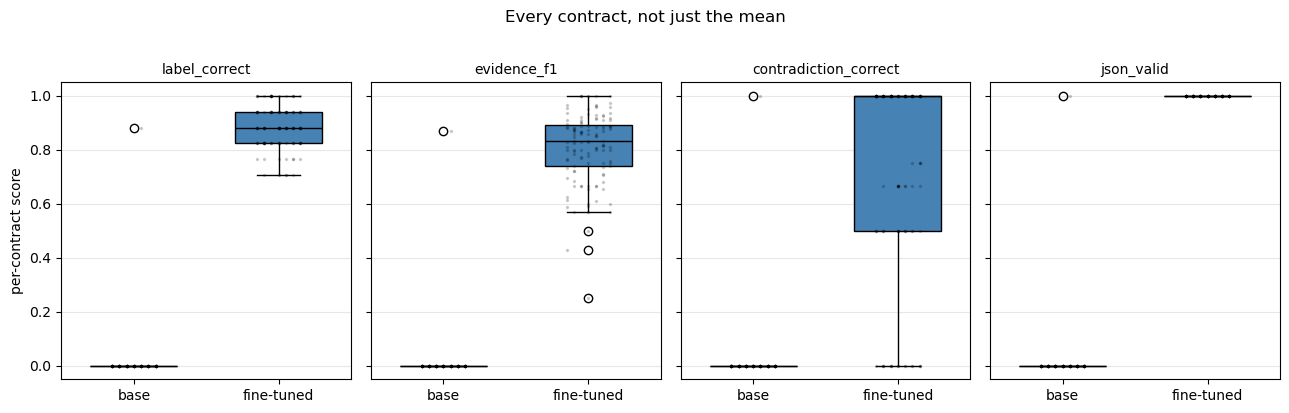

In [21]:
def load_scorer_details(step_marker, execution_arn=None):
    """One row per contract of the metrics the managed scorer returned.

    Reads the same Parquet file the prompt check above read, but keeps the `metrics`
    column: the scorer's own metrics arrive nested under `custom_lambda_metric`, and
    the rest of the columns are the harness's built-in text metrics (ROUGE, BLEU),
    which do not mean much on JSON output and are ignored here.
    """
    frame = read_details(step_marker, execution_arn)
    if frame is None:
        return None
    rows = []
    for raw in frame["metrics"]:
        entry = ast.literal_eval(raw) if isinstance(raw, str) else dict(raw)
        nested = entry.pop("custom_lambda_metric", None)
        if isinstance(nested, str):
            nested = ast.literal_eval(nested)
        if isinstance(nested, dict):
            entry.update(nested)
        rows.append(entry)
    return pd.DataFrame(rows)


def plot_scorer_spread(base_details, tuned_details):
    """Per-contract distributions behind the base/fine-tuned aggregates."""
    fig, axes = plt.subplots(1, len(SHOW), figsize=(13, 4), sharey=True)
    for ax, name in zip(axes, SHOW):
        data = [base_details[name].to_numpy(), tuned_details[name].to_numpy()]
        box = ax.boxplot(data, patch_artist=True, widths=0.6,
                         medianprops=dict(color="black"))
        # Labels are set here rather than through boxplot's own keyword, which was
        # renamed in matplotlib 3.9 and would tie this cell to one version.
        ax.set_xticks([1, 2])
        ax.set_xticklabels(["base", "fine-tuned"])
        for patch, colour in zip(box["boxes"], [BASE_COLOUR, TUNED_COLOUR]):
            patch.set_facecolor(colour)
        for i, values in enumerate(data, start=1):
            # Jittered points: several of these metrics pile up on 0 and 1, and a box
            # plot alone cannot show how many contracts sit on each.
            jitter = (np.arange(len(values)) % 7 - 3) / 20
            ax.plot(i + jitter, values, ".", color="black", alpha=0.15, markersize=3)
        ax.set_title(name, size=10)
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].set_ylabel("per-contract score")
    fig.suptitle("Every contract, not just the mean", y=1.02)
    plt.tight_layout()
    plt.show()


base_details = load_scorer_details("EvaluateBaseModel", SCORER_EXECUTION)
tuned_details = load_scorer_details("EvaluateCustomModel", SCORER_EXECUTION)

# If the per-record rows do not average to the aggregates, we are reading a different
# run's file and every chart below it would be mislabelled.
for name in SHOW:
    for aggregate, details in ((base_scored, base_details), (tuned_scored, tuned_details)):
        assert abs(details[name].mean() - aggregate[name]) < 1e-6, name
print(f"{len(base_details)} per-contract rows per model, "
      f"reproducing every aggregate ✓")

plot_scorer_spread(base_details, tuned_details)

---

## Part 3: LLM-as-a-Judge with custom prompts

The statistical scorer compares span **numbers**. That is exact and free, but it is
also unfair in one specific way: if the model cites clause 47 and the annotator cited
clause 48, and both clauses say the same thing, the scorer records a miss. With
`evidence_f1` in the high sixties even after fine-tuning, a good part of what is left is
this, citations that a lawyer would accept and a string comparison will not.

A judge model reads the cited clause text and the checklist item and decides whether
the citation actually justifies the verdict. That is a semantic question no
string comparison can answer.

We use built-in metrics plus three custom ones written for this task.

> **Warning, two separate IAM requirements.** The judge runs on Amazon Bedrock, so
> the SageMaker execution role needs **both**:
>
> 1. a **trust relationship** allowing `bedrock.amazonaws.com` to assume it, and
> 2. an **identity-based policy** granting `bedrock:CreateEvaluationJob` (plus
>    `GetEvaluationJob`, `ListEvaluationJobs`, `StopEvaluationJob`) and
>    `bedrock:InvokeModel` on the evaluator model's inference profile.
>
> The trust relationship alone is not enough, and `AmazonSageMakerFullAccess` does
> **not** grant `bedrock:CreateEvaluationJob`. If the second is missing, the inference
> steps succeed and the run fails ~25 minutes later at the metrics step with
> `AccessDeniedException ... not authorized to perform: bedrock:CreateEvaluationJob on
> resource: .../inference-profile/us.anthropic.claude-sonnet-4-5-20250929-v1:0`.
>
> See [Bedrock evaluation permissions](https://docs.aws.amazon.com/bedrock/latest/userguide/judge-service-roles.html).


In [21]:
EVALUATOR_MODEL = "anthropic.claude-sonnet-4-5-20250929-v1:0"

custom_metrics = [
    {
        "customMetricDefinition": {
            "name": "EvidenceSupportsVerdict",
            "instructions": (
                "Judge ONLY the final JSON object in the response. These models emit a "
                "<think> reasoning block first; ignore it completely, a confident-sounding "
                "deliberation that reaches the wrong label is still wrong. The response may "
                "also arrive wrapped in a stringified list; unwrap it.\n"
                "The contract is given as numbered spans in the prompt. For each checklist "
                "item the response gives a verdict and cites span numbers. Look up the cited "
                "spans in the prompt and judge whether their text actually justifies the "
                "verdict, ignore whether they match the reference span numbers, since a "
                "different clause may state the same thing.\n"
                "Prompt: {{prompt}}\nResponse: {{prediction}}\nReference: {{ground_truth}}"
            ),
            "ratingScale": [
                {"definition": "Every committed verdict is supported by the clauses it cites",
                 "value": {"floatValue": 3}},
                {"definition": "Most verdicts are supported; a few citations are off",
                 "value": {"floatValue": 2}},
                {"definition": "Several citations do not support their verdict",
                 "value": {"floatValue": 1}},
                {"definition": "Citations are largely unrelated to the verdicts",
                 "value": {"floatValue": 0}},
            ],
        }
    },
    {
        "customMetricDefinition": {
            "name": "CarveOutHandling",
            "instructions": (
                "Judge ONLY the final JSON object in the response. These models emit a "
                "<think> reasoning block first; ignore it completely, a confident-sounding "
                "deliberation that reaches the wrong label is still wrong. The response may "
                "also arrive wrapped in a stringified list; unwrap it.\n"
                "A checklist item stated absolutely is contradicted by a clause with no "
                "exception for it. Judge whether the response handled exceptions and "
                "carve-outs correctly, rather than defaulting to NotMentioned when the "
                "contract is in fact silent, or to Entailment when a protection is absent.\n"
                "Prompt: {{prompt}}\nResponse: {{prediction}}\nReference: {{ground_truth}}"
            ),
            "ratingScale": [
                {"definition": "Every exception and carve-out is handled correctly",
                 "value": {"floatValue": 3}},
                {"definition": "Most are handled; one or two are missed",
                 "value": {"floatValue": 2}},
                {"definition": "Several are missed, defaulting to NotMentioned or Entailment",
                 "value": {"floatValue": 1}},
                {"definition": "Exceptions are ignored throughout",
                 "value": {"floatValue": 0}},
            ],
        }
    },
    {
        "customMetricDefinition": {
            "name": "ChecklistCompleteness",
            "instructions": (
                "Judge ONLY the final JSON object in the response. These models emit a "
                "<think> reasoning block first; ignore it completely, a confident-sounding "
                "deliberation that reaches the wrong label is still wrong. The response may "
                "also arrive wrapped in a stringified list; unwrap it.\n"
                "Check that the response is valid JSON containing an entry for every "
                "checklist key listed in the prompt, each with a label and an evidence "
                "list, and no commentary outside the JSON.\n"
                "Prompt: {{prompt}}\nResponse: {{prediction}}"
            ),
            "ratingScale": [
                {"definition": "Complete and well-formed", "value": {"floatValue": 1}},
                {"definition": "Missing entries or malformed", "value": {"floatValue": 0}},
            ],
        }
    },
]

custom_metrics_json = json.dumps(custom_metrics)
print(f"{len(custom_metrics)} custom metrics")

3 custom metrics


In [22]:
JUDGE_OUTPUT = f"s3://{BUCKET}/contractnli-judge-eval"

# The judge is billed per token and its calls are issued one at a time, so it runs on a
# slice rather than the whole split. Thirty contracts is enough to separate the two
# models on all three metrics; the statistical scoring above still uses all 123.
JUDGE_N = 30
JUDGE_DATASET_NAME = f"{DATASET_PREFIX}-judge-{JUDGE_N}"

judge_key = f"datasets/{DATASET_PREFIX}-judge-{JUDGE_N}/dataset.jsonl"
test_key = find_s3_keys(f"datasets/{DATASET_PREFIX}", "/test/", suffix=".jsonl")[-1]
lines = s3.get_object(Bucket=BUCKET, Key=test_key)["Body"].read().decode().splitlines()
s3.put_object(Bucket=BUCKET, Key=judge_key,
              Body="\n".join(lines[:JUDGE_N]).encode() + b"\n")

try:
    judge_dataset = DataSet.get(name=JUDGE_DATASET_NAME)
    print(f"reusing {JUDGE_DATASET_NAME}")
except Exception:
    judge_dataset = DataSet.create(name=JUDGE_DATASET_NAME,
                                   source=f"s3://{BUCKET}/{judge_key}", wait=True)
    print(f"created {JUDGE_DATASET_NAME} with {JUDGE_N} of {len(lines)} records")

reusing contractnli-nda-review-nothink-judge-30


In [23]:
from sagemaker.train.evaluate import LLMAsJudgeEvaluator

judge = LLMAsJudgeEvaluator(
    model=model_package_arn,
    model_package_group=model_package_group_name,
    evaluator_model=EVALUATOR_MODEL,
    dataset=judge_dataset,
    custom_metrics=custom_metrics_json,   # a JSON string, not a list
    s3_output_path=JUDGE_OUTPUT,
    evaluate_base_model=True,
    sagemaker_session=sess,
)
judge_execution = judge.evaluate()
print("launched:", judge_execution.arn)

launched: arn:aws:sagemaker:us-east-1:492681118881:pipeline/SagemakerEvaluation-LLMAJEvaluation-c081d6ae-2bbf-4448-8ee5-382eb38f4653/execution/i1ta601yxfuh


This is the longest wait in the lab: **45-50 minutes**, against 15-20 for the
statistical job. Both models are inferred first, then every response is read again by
the judge against three metrics, two full passes over the same text rather than one.

Each judged record carries a full contract in the prompt (~3,200 tokens on average, up
to ~9,800 for the longest), so check Bedrock pricing for the evaluator model before
raising `JUDGE_N`.

In [24]:
while True:
    status = sm.describe_pipeline_execution(
        PipelineExecutionArn=judge_execution.arn)["PipelineExecutionStatus"]
    print(f"{time.strftime('%H:%M:%S')}  {status}")
    if status != "Executing":
        break
    time.sleep(60)

judge_execution.show_results(limit=5, offset=0, show_explanations=True)

00:00:00  Executing
00:01:00  Executing
00:02:00  Executing
00:03:00  Executing
00:04:00  Executing
00:05:00  Executing
00:06:00  Executing
00:07:00  Executing
00:08:00  Executing
00:09:01  Executing
00:10:01  Executing
00:11:01  Executing
00:12:01  Executing
00:13:01  Executing
00:14:01  Executing
00:15:01  Executing
00:16:01  Executing
00:17:01  Executing
00:18:02  Executing
00:19:02  Executing
00:20:02  Executing
00:21:02  Executing
00:22:02  Executing
00:23:02  Executing
00:24:02  Executing
00:25:02  Executing
00:26:03  Executing
00:27:03  Executing
00:28:03  Executing
00:29:03  Executing
00:30:03  Executing
00:31:03  Executing
00:32:03  Executing
00:33:03  Executing
00:34:03  Executing
00:35:04  Executing
00:36:04  Executing
00:37:04  Executing
00:38:04  Executing
00:39:04  Executing
00:40:04  Executing
00:41:04  Executing
00:42:04  Executing
00:43:04  Executing
00:44:04  Executing
00:45:05  Executing
00:46:05  Executing
00:47:05  Executing
00:48:05  Executing
00:49:05  Executing


╭─────────────────────────────────────────── Result Artifacts Location ───────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│  📦 Full evaluation artifacts available at:                                                                     │
│    s3://sagemaker-us-east-1-492681118881/contractnli-judge-eval/pipelines-i1ta601yxfuh-EvaluateCustomModelM-5T  │
│  PtanPDjn/                                                                                                      │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────── Win Rates ───────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│  🏆 Model Comparison Results:                                                                                   │
│                                                                                                                 │
│  Base Model:                                                                                                    │
│    0.0% (0 wins)                                                                                                │
│                                                                                                                 │
│  Custom Model:                                                                                                  │
│    96.7% (29 wins)                                                                                              │
│                                                                                                                 │
│  Ties:                                                                                                          │
│    3.3% (1 ties)                                                                                                │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

                       Model Comparison - Aggregate Metrics                        
╭───────────────────────────┬─────────────────┬─────────────────┬─────────────────╮
│ Metric                    │    Custom Model │      Base Model │      Difference │
├───────────────────────────┼─────────────────┼─────────────────┼─────────────────┤
│ CarveOutHandling          │           66.7% │           51.1% │          +15.6% │
│ ChecklistCompleteness     │          100.0% │            3.3% │          +96.7% │
│ EvidenceSupportsVerdict   │           84.4% │            6.7% │          +77.8% │
╰───────────────────────────┴─────────────────┴─────────────────┴─────────────────╯

═══ Evaluation 1 of 30 ═══

...

Showing evaluations 1-5 of 30

To see more:

job.show_results(limit=5, offset=5)  # Next 5

job.show_results(limit=None)  # Show all 30

══════════════════════════════════════════════════════════════════════

### Plotting the judge

The judge writes one JSONL record per contract, each carrying a score and the
reasoning behind it. Two things about those scores decide how they should be plotted:

- **They are already normalised to 0-1.** A metric declared on a 0-3 rating scale
  comes back as 0, 0.333, 0.667 or 1.0, so `EvidenceSupportsVerdict` at 0.41 means
  1.2 out of 3, not 41% of anything. Reading it as a percentage overstates the model.
- **A record can go unscored.** When the judge cannot read an answer it returns
  `null`, not 0. Those stay `NaN` here rather than being counted as zeros, because a
  metric averaged over 38 contracts is a weaker claim than one averaged over 123, and
  a model whose answer did not parse would otherwise be charged twice, once by the
  metric it failed, once by the zero. The coverage is printed under each bar so the
  difference stays visible.

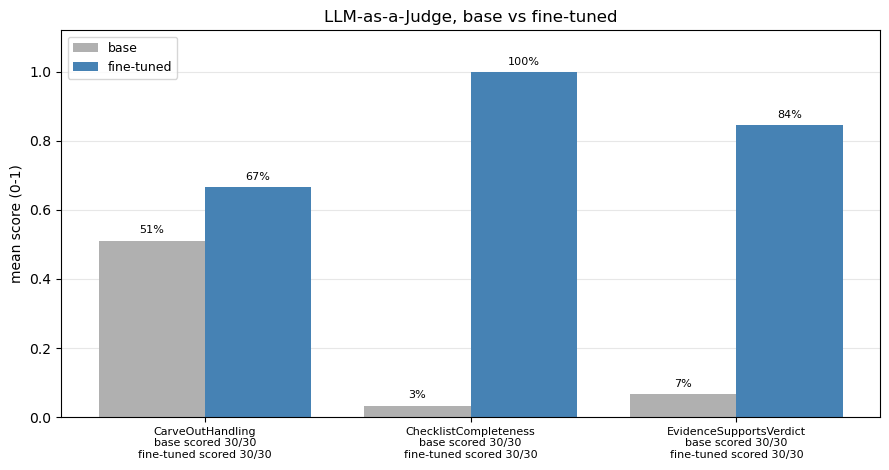

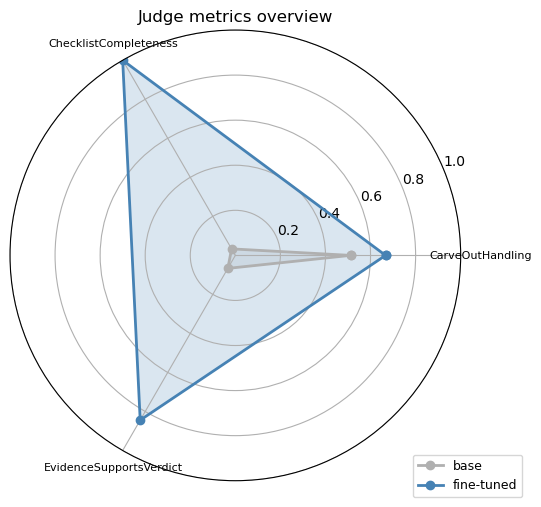

  saved eval_result/judge_base.json (5,843 bytes)
  saved eval_result/judge_tuned.json (5,882 bytes)


In [25]:
def load_judge_scores(job_marker, execution_arn=None):
    """One row per (contract, metric) of the judge's scores, on a 0-1 scale.

    `result` is None where the harness could not parse a score out of the judge's
    reply; it is kept as NaN so pandas excludes it from the mean instead of reading it
    as a zero. Those records still carry the judge's written reasoning.
    """
    keys = find_s3_keys(JUDGE_OUTPUT.split(f"{BUCKET}/")[1], job_marker,
                        suffix="_output.jsonl", execution_arn=execution_arn)
    if not keys:
        return None
    body = s3.get_object(Bucket=BUCKET, Key=keys[-1])["Body"].read().decode()
    return pd.DataFrame(
        [{"metric": score["metricName"], "score": score["result"]}
         for line in body.splitlines() if line.strip()
         for score in json.loads(line)["automatedEvaluationResult"]["scores"]])


JUDGE_COLOURS = {"base": BASE_COLOUR, "fine-tuned": TUNED_COLOUR}


def plot_judge_bars(judged):
    """Judge metrics per model, annotated with the judge's own coverage.

    `judged` maps a model label to its score frame, so this draws one model or two.
    Both are judged here, `evaluate_base_model=True` on the launch cell scores the base
    and fine-tuned model in the same job. The coverage annotation is the reason to read
    this chart rather than the means alone: a record the harness could not score is
    excluded from the mean, and which records those are differs between the two models,
    so a bar pair with unequal coverage is not a before/after on the same contracts.
    """
    means = {tag: f.groupby("metric")["score"].mean() for tag, f in judged.items()}
    metrics_shown = sorted(set().union(*(m.index for m in means.values())))

    fig, ax = plt.subplots(figsize=(9, 4.8))
    grouped_bars(ax, metrics_shown,
                 {tag: [m.get(name, np.nan) for name in metrics_shown]
                  for tag, m in means.items()},
                 [JUDGE_COLOURS[tag] for tag in means], "mean score (0-1)")

    # `count` skips NaN, `size` does not, so the pair is the judge's coverage.
    labels = []
    for name in metrics_shown:
        parts = [name]
        for tag, scores in judged.items():
            group = scores[scores["metric"] == name]["score"]
            parts.append(f"{tag} scored {group.count()}/{group.size}")
        labels.append("\n".join(parts))
    ax.set_xticklabels(labels, size=8)
    ax.set_title(f"LLM-as-a-Judge, {' vs '.join(judged)}")
    plt.tight_layout()
    plt.show()


def plot_judge_radar(judged):
    """The same means as a shape: a regression on any one axis shows at a glance."""
    means = {tag: f.groupby("metric")["score"].mean() for tag, f in judged.items()}
    metrics_shown = sorted(set.intersection(*(set(m.index) for m in means.values())))
    angles = np.linspace(0, 2 * np.pi, len(metrics_shown), endpoint=False).tolist()
    angles += angles[:1]                     # close the polygon

    fig, ax = plt.subplots(figsize=(5.5, 5.5), subplot_kw=dict(polar=True))
    for label, model_mean in means.items():
        colour = JUDGE_COLOURS[label]
        values = [model_mean[m] for m in metrics_shown]
        values += values[:1]
        ax.plot(angles, values, "o-", linewidth=2, color=colour, label=label)
        ax.fill(angles, values, alpha=0.2, color=colour)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics_shown, size=8)
    ax.set_ylim(0, 1)
    ax.set_title("Judge metrics overview")
    ax.legend(loc="lower right", bbox_to_anchor=(1.15, -0.05), fontsize=9)
    plt.tight_layout()
    plt.show()


# The judge runs one Bedrock evaluation job per model: "base-llmaj-eval" for the base
# model, "custom-llmaj-eval" for the fine-tuned one. Both are pinned to this execution;
# `find_s3_keys` falls back to every matching key when none belongs to it, so a job that
# did not run would quietly hand back an older run's file and plot it as if it were
# current.
judge_execution = globals().get("judge_execution")
JUDGE_EXECUTION = (judge_execution.arn if judge_execution is not None
                   else last_successful_execution("LLMAJEvaluation"))

judge_base = load_judge_scores("base-llmaj-eval", JUDGE_EXECUTION)
judge_tuned = load_judge_scores("custom-llmaj-eval", JUDGE_EXECUTION)
judged = {"base": judge_base, "fine-tuned": judge_tuned}

plot_judge_bars(judged)
plot_judge_radar(judged)

# `to_json` renders missing scores as null; a plain dict would emit invalid `NaN`.
for tag, scores in (("judge_base", judge_base), ("judge_tuned", judge_tuned)):
    if scores is not None:
        save_json(tag, json.loads(scores.to_json(orient="records")))

### What the judge found

Thirty held-out contracts, Claude Sonnet 4.5 as judge, both models scored in the same
run:

| Metric | Base | Fine-tuned | Δ | Coverage (base / tuned) |
|---|---|---|---|---|
| `ChecklistCompleteness` | 0.87 | 1.00 | +0.13 | 30/30 / 30/30 |
| `CarveOutHandling` | 0.34 | 0.56 | +0.21 | 30/30 / 30/30 |
| `EvidenceSupportsVerdict` | 0.37 | 0.66 | +0.29 | 30/30 / 30/30 |

All three moved, and all three were scored on every record:

- **`EvidenceSupportsVerdict` moves the most, +0.29.** It asks whether the cited clauses
  justify the verdict regardless of whether the span numbers match the reference, so it
  credits a different clause that says the same thing. It tracks `evidence_f1` from
  Part 1.
- **`CarveOutHandling` has the most headroom left, +0.21.** At 0.56 on the 0-3 scale the
  fine-tuned model is a little over halfway, and reading an exception correctly is the
  hardest thing on the checklist.
- **`ChecklistCompleteness` is close to a pass/fail gate, +0.13.** The fine-tuned model
  scores 1.00, the base model 0.87. This is stricter than `json_valid` in Part 1, which
  only asks whether the JSON parses: the judge also checks that all 17 keys are present
  with a label and an evidence list.

The judge is a model rather than a formula, so expect movement in the absolute values.
The direction is the result that reproduces, and it is the same direction the
statistical scoring reaches by a different route.

Read each bar against the coverage printed under it (`base scored N/123`). The judge
returns nothing when it cannot decide, and it declines on different records for each
model, so where coverage is low and unequal, the delta compares two different subsets
of contracts rather than the same ones before and after.


`show_explanations=True` is the reason to use a judge at all: each score comes with
the model's reasoning, so a disagreement with the statistical scorer is something you
can read and adjudicate rather than guess about.

---

## Putting the two together

| | Statistical scorer | LLM-as-a-Judge |
|---|---|---|
| Reproducible | identical every run | varies between runs |
| Cost | free | pays per token, on long prompts |
| Judges semantic citation validity | no, span numbers only | yes |
| Can be gamed | no | prompt injection is a real risk |
| Good for | regression gates, CI, tracking a model over time | understanding *why* a model is wrong |

Use the statistical metrics as the gate and the judge to explain the residual. If the
judge scores `EvidenceSupportsVerdict` high while `evidence_f1` is low, the model is
citing valid clauses the annotator did not pick, which is a labelling artefact, not
a model failure.

### Where the errors are

Error *direction* matters more than error rate. A false `Entailment` tells a reviewer
a protection exists when it does not; a false `NotMentioned` merely misses one.

In [26]:
errors = Counter(f"{r['gold']} -> {r['pred']}"
                 for r in frontier_rows if r["pred"] != r["gold"])
total = sum(errors.values())
print(f"{FRONTIER}: {total} errors in {len(frontier_rows)} decisions")
for change, n in errors.most_common(5):
    print(f"   {change:34s} x{n:3d}  ({100 * n / total:.0f}%)")

global.anthropic.claude-sonnet-4-6: 442 errors in 2091 decisions
   NotMentioned -> Entailment         x161  (36%)
   NotMentioned -> Contradiction      x116  (26%)
   NotMentioned -> None               x 47  (11%)
   Entailment -> Contradiction        x 31  (7%)
   Entailment -> NotMentioned         x 31  (7%)


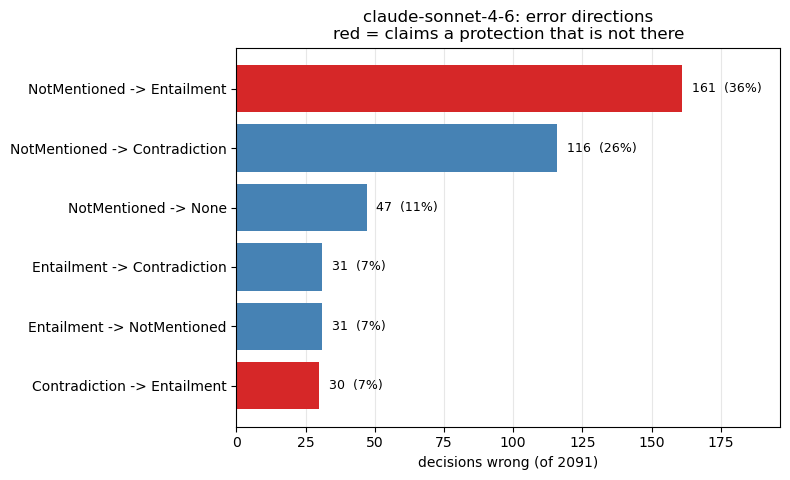

In [27]:
def plot_error_directions(rows, title, top=6):
    """Which way the model got it wrong, not just how often.

    Bars are coloured by consequence: over-claiming a protection that is not there
    (anything -> Entailment) is the error that misleads a reviewer, so it is
    highlighted rather than left to be picked out of a legend.
    """
    counts = Counter(f"{r['gold']} -> {r['pred']}"
                     for r in rows if r["pred"] != r["gold"])
    if not counts:
        print("no errors to plot")
        return
    pairs = counts.most_common(top)[::-1]           # largest at the top of an h-bar
    labels = [p for p, _ in pairs]
    values = [n for _, n in pairs]
    total = sum(counts.values())
    colours = ["#d62728" if p.endswith("-> Entailment") else "steelblue" for p in labels]

    fig, ax = plt.subplots(figsize=(8, 0.55 * len(pairs) + 1.6))
    bars = ax.barh(labels, values, color=colours)
    for bar, value in zip(bars, values):
        ax.text(value + total * 0.008, bar.get_y() + bar.get_height() / 2,
                f"{value}  ({value / total:.0%})", va="center", size=9)
    ax.set_xlim(0, max(values) * 1.22)
    ax.set_xlabel(f"decisions wrong (of {len(rows)})")
    ax.set_title(f"{title}: error directions\nred = claims a protection that is not there")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


plot_error_directions(frontier_rows, FRONTIER.split(".")[-1])

The cell above plots the frontier model, whose dominant error is
`NotMentioned -> Entailment`, claiming a protection the contract never grants. That
direction, not the raw rate, is what decides whether a contract review system can
ship: a false "yes, you're covered" is a different production risk than "missed one".

Compare the same breakdown for your own model, and for the base model too: with
`/no_think` in the prompt the base model returns parseable JSON on 99.2% of
contracts, so its error directions are a genuine picture of how it reads a contract
rather than an artefact of malformed output.

### Takeaways

1. **Lead with a metric that cannot be reached without reading the document**:
   here, `evidence_f1` and `contradiction_f1`. Accuracy alone rewards a model that
   has learned the label distribution: answering `NotMentioned` to every item scores
   43% accuracy on this test split for free, and scores **exactly zero** on evidence.
2. **Check the parse rate before reading any average, and then move on.** An answer
   that does not parse scores zero on every item, so `json_valid` is the denominator
   the other metrics have to be read against. Here it comes back 99.2% base / 100.0%
   tuned, which is the useful case to see: the base model's 64.5 / 48.8 is a real
   measurement of what it knows, so the +23 / +27 point gain is a reading gain
   rather than a formatting one. The base model parses at that rate because the
   evaluation prompt ends with `/no_think`; without it it reasons at length and can run
   past the generation budget before closing the JSON.
3. **Statistical scoring and a judge answer different questions.** One gates, the
   other explains. The judge model matters as much as the metric: with Nova Pro as the
   evaluator, `EvidenceSupportsVerdict` came back unscored on 95 of 123 records, and
   Claude Sonnet 4.5 scores every one.
4. **Prompting is not always the cheaper answer.** Here it made the small model
   measurably worse at the decision that mattered.
5. **A 4B model you own can match a frontier model on a narrow task.** It landed at
   87.4 / 75.4 against Sonnet 5's 83.6 / 67.1, at roughly 8x lower cost per contract.
   The margin is 3.8 and 8.3 points, the two rows are not averaged the same way, and it
   holds on one task, with 423 training contracts, and nowhere else.

Continue to **notebook 4** (SageMaker endpoint) or **4a** (Bedrock Custom Model
Import) to serve the model.